[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HesusG/dammg-supervisado/blob/main/notebooks/demos/D2_ridge_svd.ipynb)

# D2 · Ridge: encogimiento por dirección y prior gaussiano

*DAMMG · Módulo VI · Aprendizaje supervisado · FC-UNAM*

**Recuerden (Mód I + Mód V).** SVD $X=UDV^\top$. Bayes: posterior $\propto$ verosimilitud $\times$ prior; MAP = moda de la posterior.

**Supuestos.** $X$ y $\vec y$ centrados (no se regulariza $b$), variables estandarizadas, $\lambda>0$ en escala de suma: $\lVert\vec y-X\vec w\rVert^2+\lambda\lVert\vec w\rVert^2$ (= `Ridge(alpha=λ)`). Para MAP: ruido $\mathcal N(0,\sigma^2)$ i.i.d. y prior $\vec w\sim\mathcal N(\vec 0,\tfrac{\sigma^2}{\lambda}I)$.

**La idea.** Ridge multiplica la componente de $\vec y$ en cada dirección principal $\vec u_j$ por $s_j=\dfrac{d_j^2}{d_j^2+\lambda}$. Las direcciones de poca varianza (las casi colineales) se apagan primero.

La derivación completa está en `anexos/derivaciones.pdf`.

In [1]:
%matplotlib inline
import sys, pathlib
# dammg_utils vive en notebooks/ (en Colab se descarga junto al notebook)
for p in (pathlib.Path("..").resolve(), pathlib.Path(".").resolve()):
    if (p / "dammg_utils.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import matplotlib.pyplot as plt
from dammg_utils import estilo_dammg, COLORES
estilo_dammg()
C = COLORES
np.set_printoptions(precision=4, suppress=True)

## Parámetros
Si los controles no aparecen (por ejemplo, en el PDF), cambien el valor aquí y ejecuten de nuevo.

In [2]:
# Parámetro del ¿qué pasa si...?
LOG10_LAMBDA = 0.5   # λ = 10**LOG10_LAMBDA, escala de suma (sklearn alpha)

## La identidad, con números

valores singulares d_j: [13.4158 11.7417  9.0173  0.8625  0.3019]
λ = 3.16
  SVD     : [ 1.3482  1.0553 -1.5865  0.7626 -0.3674]
  cerrada : [ 1.3482  1.0553 -1.5865  0.7626 -0.3674]
  sklearn : [ 1.3482  1.0553 -1.5865  0.7626 -0.3674]
  MAP     : [ 1.3482  1.0553 -1.5865  0.7626 -0.3674]
  s_j = d²/(d²+λ): [0.9827 0.9776 0.9626 0.1905 0.028 ]   df(λ) = 3.14


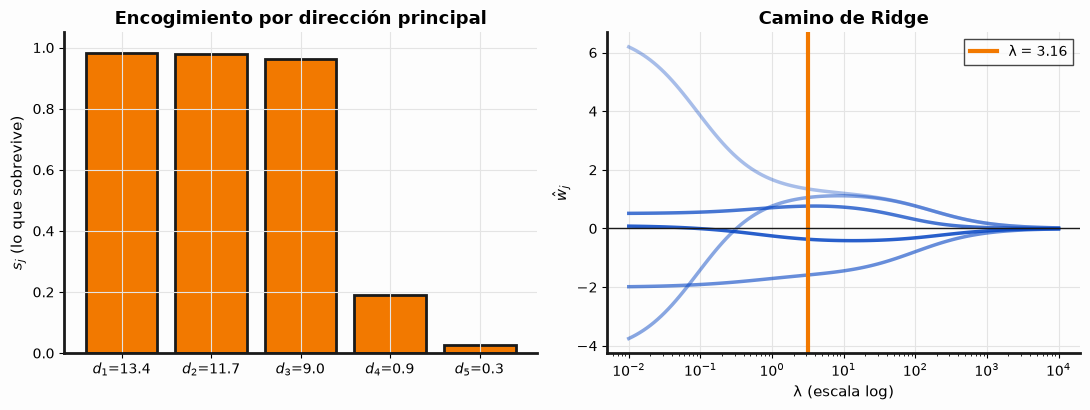

In [3]:
from sklearn.linear_model import Ridge
from scipy.optimize import minimize
from dammg_utils import ridge_svd, factores_encogimiento

rng = np.random.default_rng(1)
m, n = 80, 5
Z = rng.normal(size=(m, 3))
X = np.column_stack([Z[:, 0], Z[:, 0] + 0.05 * rng.normal(size=m),   # dos columnas casi iguales
                     Z[:, 1], Z[:, 2], 0.5 * Z[:, 1] + 0.5 * Z[:, 2] + 0.1 * rng.normal(size=m)])
X = (X - X.mean(0)) / X.std(0)
y = X @ np.array([1.5, 1.0, -2.0, 0.5, 0.0]) + rng.normal(scale=1.0, size=m)
y = y - y.mean()
d = np.linalg.svd(X, compute_uv=False)
print("valores singulares d_j:", d)

def demo(log10_lam=LOG10_LAMBDA):
    lam = 10 ** log10_lam
    w_svd = ridge_svd(X, y, lam)
    w_cerr = np.linalg.solve(X.T @ X + lam * np.eye(n), X.T @ y)
    w_skl = Ridge(alpha=lam, fit_intercept=False).fit(X, y).coef_
    # MAP: −log posterior con σ² = 1 y τ² = σ²/λ
    sigma2 = 1.0; tau2 = sigma2 / lam
    nlp = lambda w: ((y - X @ w) @ (y - X @ w)) / (2 * sigma2) + (w @ w) / (2 * tau2)
    w_map = minimize(nlp, np.zeros(n), method="BFGS", options={"gtol": 1e-10}).x
    print(f"λ = {lam:.3g}")
    print("  SVD     :", w_svd)
    print("  cerrada :", w_cerr)
    print("  sklearn :", w_skl)
    print("  MAP     :", w_map)
    assert np.allclose(w_svd, w_cerr) and np.allclose(w_svd, w_skl, atol=1e-6)
    assert np.allclose(w_svd, w_map, atol=1e-4)
    s = factores_encogimiento(X, lam)
    print("  s_j = d²/(d²+λ):", s, f"  df(λ) = {s.sum():.2f}")

    lams = np.logspace(-2, 4, 120)
    camino = np.array([ridge_svd(X, y, l) for l in lams])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].bar([f"$d_{j+1}$={d[j]:.1f}" for j in range(n)], s, color=C["lambda"], edgecolor=C["tinta"], linewidth=2)
    ax[0].set(ylim=(0, 1.05), ylabel="$s_j$ (lo que sobrevive)", title="Encogimiento por dirección principal")
    for j in range(n):
        ax[1].semilogx(lams, camino[:, j], color=C["w"], alpha=0.35 + 0.13 * j)
    ax[1].axvline(lam, color=C["lambda"], linewidth=3, label=f"λ = {lam:.3g}")
    ax[1].axhline(0, color=C["tinta"], linewidth=1)
    ax[1].set(xlabel="λ (escala log)", ylabel="$\\hat w_j$", title="Camino de Ridge")
    ax[1].legend(loc="upper right")
    fig.tight_layout(); plt.show()

demo()

**¿Qué pasa si…?** Predigan: al subir $\lambda$, ¿qué barra baja primero, la de $d_1$ o la de $d_5$? ¿Qué pareja de coeficientes se "pone de acuerdo" primero en el camino?

Respuesta esperada: baja primero la dirección con $d_j$ más chico (la diferencia entre las dos columnas casi iguales). Los coeficientes de esas dos columnas se juntan y luego todos tienden a 0. Con $\lambda\to 0$ regresa OLS.

In [4]:
# ¿Qué pasa si...? Muevan el control. Sin ipywidgets: cambien el parámetro arriba y vuelvan a ejecutar.
try:
    import ipywidgets as W
    W.interact(demo, log10_lam=W.FloatSlider(value=LOG10_LAMBDA, min=-2, max=4, step=0.1, description='log₁₀ λ', continuous_update=False))
except ImportError:
    print('ipywidgets no está instalado: usen la celda de parámetros.')